# The Kiwi Challenge: From Naive Thresholding to 3D Segmentation & Semi-Verifiability

*BMED365 — Computational Imaging, Modeling and AI in Biomedicine (Spring 2027)*  
*Updated by Arvid Lundervold — runs locally with `uv` (`bmed365-2027` kernel) or in Google Colab (originally from BMED360, 2019)*

> **Kiwi Challenge Notebook Trilogy (`Lab4-Comp-Imag/Kiwi-challenge`):**
> 1. `01-kiwi-explore.ipynb` — 3D NIfTI/DICOM headers, voxel geometry & coordinate systems
> 2. `02-kiwi-seeds-explore.ipynb` — 2D single-slice filtering, thresholding, unsupervised K-means & the Dagstuhl/CUHK 3D variational milestone
> 3. **`03-kiwi-paradigms-and-verification.ipynb` (this notebook)** — Full 3D segmentation ladder, quantitative "lesion load", & the **4-Panel Semi-Verifiability Dashboard**

---

### Why a Kiwifruit in a Biomedical AI Course?

In **Lecture 1**, we posed a deceptively simple question about an intact kiwifruit scanned in our preclinical **7 T Bruker MRI scanner** at UiB:

> **1. How many seeds ($N$) are inside this kiwifruit?**  
> **2. If the kiwifruit were a brain and the seeds were focal lesions (e.g., MS plaques or cerebral microbleeds), what is its "lesion load" ($V_{\text{seeds}} / V_{\text{kiwi}}$)?**  
> **3. How can we *verify* whether an algorithm — or an AI coding agent — is right when nobody ever dissected the fruit to count the seeds?** *(Compare Prof. Raymond H. Chan's 2012 question on Xiaohao Cai's 3D variational isosurfaces at the end of `02-kiwi-seeds-explore.ipynb`: "Could you give us comments as to the quality of the segmentation?")*

This notebook implements the **Lab 4 live comparative walkthrough**:
- **Step 0:** Load the 3D 7T MRI scan (`256 × 256 × 128` anisotropic voxels) and measure whole-fruit ("brain") volume in physical $\text{mm}^3$.
- **Step 1:** Build a **4-Panel Semi-Verifiability Dashboard** *before* trusting any seed count (multi-planar overlays, physical single-seed volume bounds, radial anatomy checks, threshold stability, and synthetic 3D seed injection).
- **Step 2 (Rung 1):** Test **naive 3D intensity thresholding** — and watch every verification check catch why raw MRI intensity $\neq$ biological structure.
- **Step 3 (Rung 2A):** Extend the **2D morphological top-hat + K-means clustering** idea from `02-kiwi-seeds-explore.ipynb` to the full 3D volume.
- **Step 4 (Rung 2B):** Build a **3D anisotropic seedness + bright-locule context + 3D marker-controlled watershed** pipeline that respects voxel physics and separates touching seeds.
- **Step 5:** Compare all rungs side-by-side, perform a **zoomed visual micro-audit**, and set up **Rungs 3–5** (Vision Foundation Models, 3D Deep Learning, and Verifier-Guided AI Agents).

## Step 0 — Environment Setup & 3D MRI Data Loading

This notebook works both **locally** (reading from `../data/`) and in **Google Colab** (automatically downloading the 14 MB NIfTI file from the public `BMED365-2027` repository if needed).

In [1]:
import os
import time
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from skimage import filters, morphology, segmentation, measure
from sklearn.cluster import MiniBatchKMeans

try:
    import nibabel as nib
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "nibabel"])
    import nibabel as nib

plt.rcParams["figure.dpi"] = 115
plt.rcParams["axes.titlesize"] = 11

# Locate NIfTI volume locally or download automatically in Google Colab
NII_NAME = "kiwi_20050217191129_131073_RARE_high_res_axial.nii.gz"
local_candidates = [
    Path("../data") / NII_NAME,
    Path("Lab4-Comp-Imag/Kiwi-challenge/data") / NII_NAME,
    Path("data") / NII_NAME,
]
nii_path = next((p for p in local_candidates if p.exists()), None)

if nii_path is None:
    nii_path = Path("data") / NII_NAME
    nii_path.parent.mkdir(parents=True, exist_ok=True)
    url = f"https://raw.githubusercontent.com/arvidl/BMED365-2027/main/Lab4-Comp-Imag/Kiwi-challenge/data/{NII_NAME}"
    print(f"Downloading {NII_NAME} from GitHub for Colab session...")
    urllib.request.urlretrieve(url, nii_path)

img = nib.load(str(nii_path))
vol = img.get_fdata(dtype=np.float32)
spacing = tuple(float(s) for s in img.header.get_zooms()[:3])  # (dx, dy, dz) in mm
voxel_vol_mm3 = float(np.prod(spacing))

print(f"Loaded NIfTI file : {nii_path}")
print(f"3D matrix shape   : {vol.shape}  ({vol.size:,} voxels)")
print(f"Voxel spacing     : {spacing[0]:.4f} x {spacing[1]:.4f} x {spacing[2]:.4f} mm")
print(f"Single-voxel vol. : {voxel_vol_mm3:.5f} mm^3  (~{1.0 / voxel_vol_mm3:.1f} voxels per mm^3)")
print(f"Intensity range   : [{vol.min():.0f}, {vol.max():.0f}]")

Loaded NIfTI file : ../data/kiwi_20050217191129_131073_RARE_high_res_axial.nii.gz
3D matrix shape   : (256, 256, 128)  (8,388,608 voxels)
Voxel spacing     : 0.2344 x 0.2344 x 0.5000 mm
Single-voxel vol. : 0.02747 mm^3  (~36.4 voxels per mm^3)
Intensity range   : [71, 32766]


### Whole-Fruit ("Brain") Mask & MRI Contrast Physics

Notice two critical physical properties of this 7 T $T_2$-weighted RARE scan:
1. **Anisotropic slices:** The slice thickness (`0.50 mm`) is more than **twice** the in-plane pixel width (`0.234 mm`). Any 3D filter or distance transform must use physical millimeter spacing rather than raw array indices.
2. **Contrast inversion of the central core:** In an optical photograph, the central core (*columella*) of a kiwifruit looks bright white. In $T_2$-weighted MRI (`TE = 63.9 ms`), dense fibrous tissue has a short $T_2$ relaxation time and appears **dark** — just like the seeds! Meanwhile, the water-rich gel inside the radial seed chambers (*locules*) appears **bright**.

Let us first segment the **whole kiwifruit 3D mask** (analogous to *skull-stripping / brain extraction* in neuroimaging) so we can measure whole-fruit volume $V_{\text{kiwi}}$ and compute normalized radial coordinates $r / R(z)$ from the central axis of the fruit.

Whole-kiwi ('brain') voxels : 3,130,076
Whole-kiwi physical volume  : 85,970 mm^3  (85.97 cm^3)


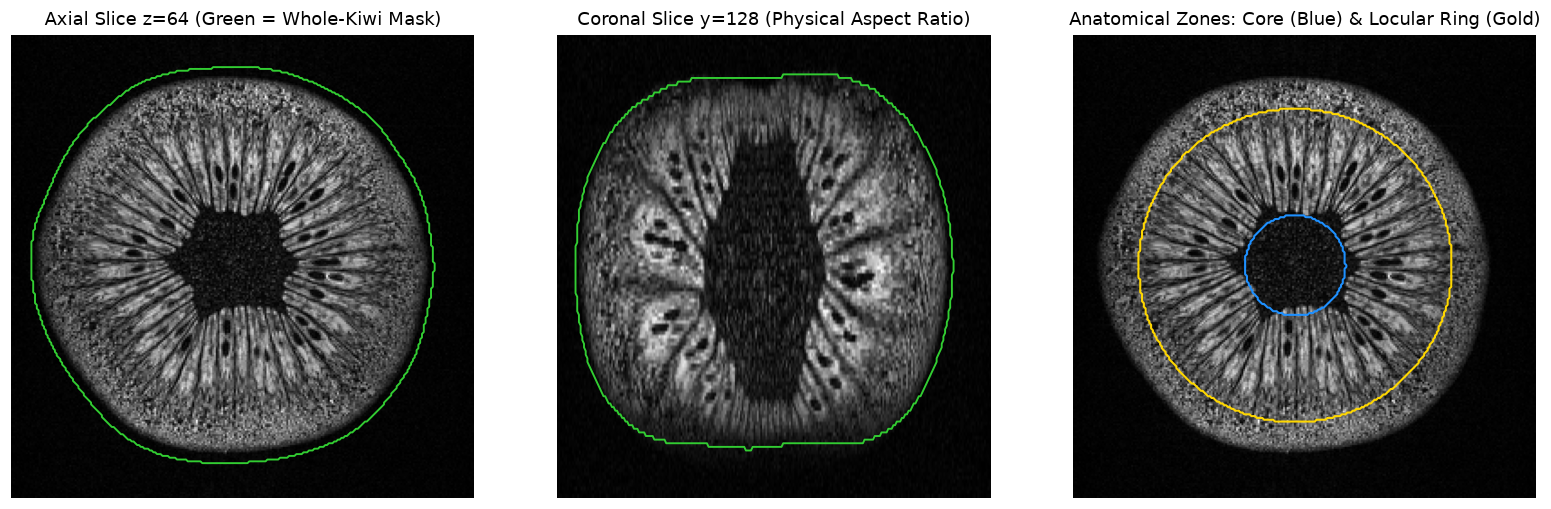

In [2]:
# Smooth in physical 3D space (1.2 mm sigma) to bridge dark pores in the peel, then Otsu + hole filling
vol_smooth_fg = ndi.gaussian_filter(
    vol, sigma=(1.2 / spacing[0], 1.2 / spacing[1], 1.2 / spacing[2])
)
fg_thresh = filters.threshold_otsu(vol_smooth_fg[::2, ::2, ::2]) * 0.35
fruit_raw = vol_smooth_fg > fg_thresh

# Fill interior holes slice-by-slice and in 3D so the dark central columella is included inside the fruit mask
fruit_filled = np.zeros_like(fruit_raw)
for z in range(vol.shape[2]):
    fruit_filled[:, :, z] = ndi.binary_fill_holes(fruit_raw[:, :, z])
fruit_filled = ndi.binary_fill_holes(fruit_filled)

lbl_fg, _ = ndi.label(fruit_filled)
largest_cc = 1 + int(np.argmax(np.bincount(lbl_fg.ravel())[1:]))
fruit_mask = lbl_fg == largest_cc
fruit_interior = ndi.binary_erosion(fruit_mask, iterations=3)  # ~0.7 mm inside outer skin

fruit_vol_mm3 = fruit_mask.sum() * voxel_vol_mm3
fruit_vol_cm3 = fruit_vol_mm3 / 1000.0
print(f"Whole-kiwi ('brain') voxels : {fruit_mask.sum():,}")
print(f"Whole-kiwi physical volume  : {fruit_vol_mm3:,.0f} mm^3  ({fruit_vol_cm3:.2f} cm^3)")

# Compute normalized radial distance r / R(z) within each axial slice:
#   r/R < 0.25  -> central fibrous columella (core: should have ~0 seeds)
#   0.25..0.78  -> radial locular ring (anatomical seed zone)
#   r/R > 0.78  -> outer pericarp & skin (should have ~0 seeds)
r_norm = np.full(vol.shape, 1.5, dtype=np.float32)
ix, iy = np.indices(vol.shape[:2], dtype=np.float32)
for z in range(vol.shape[2]):
    m = fruit_mask[:, :, z]
    area = int(m.sum())
    if area < 50:
        continue
    cx, cy = ndi.center_of_mass(m)
    R_eq = np.sqrt(area / np.pi)
    r_norm[:, :, z] = np.sqrt((ix - cx) ** 2 + (iy - cy) ** 2) / max(R_eq, 1.0)

# Visualize Axial (z=64) and Coronal (y=128) views with whole-fruit contour and anatomical zones
z_mid, y_mid = 64, 128
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))

axes[0].imshow(vol[:, :, z_mid].T, cmap="gray", origin="lower")
axes[0].contour(fruit_mask[:, :, z_mid].T, levels=[0.5], colors="limegreen", linewidths=1.2)
axes[0].set_title(f"Axial Slice z={z_mid} (Green = Whole-Kiwi Mask)")

axes[1].imshow(vol[:, y_mid, :].T, cmap="gray", origin="lower", aspect=spacing[2] / spacing[0])
axes[1].contour(fruit_mask[:, y_mid, :].T, levels=[0.5], colors="limegreen", linewidths=1.2)
axes[1].set_title(f"Coronal Slice y={y_mid} (Physical Aspect Ratio)")

axes[2].imshow(vol[:, :, z_mid].T, cmap="gray", origin="lower")
axes[2].contour((r_norm[:, :, z_mid] < 0.25).T, levels=[0.5], colors="dodgerblue", linewidths=1.3)
axes[2].contour((r_norm[:, :, z_mid] < 0.78).T, levels=[0.5], colors="gold", linewidths=1.3)
axes[2].set_title("Anatomical Zones: Core (Blue) & Locular Ring (Gold)")

for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## Step 1 — Designing the "Semi-Verifiability" Harness *Before* Segmenting

In real biomedical research — and especially when working with **AI coding assistants or autonomous agents** — generating code that outputs `N = 950` takes seconds. Knowing whether `950` counts **actual seeds** rather than peel speckles and fibrous septa is the real scientific problem.

Because no complete voxel-by-voxel manual segmentation exists for all 128 slices, we combine **four independent verification checks** into a single reusable evaluation harness:

1. **Multi-Planar Visual Overlay (Axial + Coronal):** Does each colored 3D label cover one real seed smoothly across slices without leaking into the dark core or outer skin?
2. **Physical Single-Seed Volume Histogram ($\text{mm}^3$):** Botanical *Actinidia deliciosa* seeds have a volume of roughly **`0.35–3.5 mm³`** (`~13–127 voxels`). Spikes below `0.35 mm³` indicate noise specks; objects above `3.5 mm³` indicate merged seed clusters or core/skin leaks.
3. **Anatomical Radial Zone Profile ($r / R$):** Real seeds reside strictly inside the mucilaginous locular ring (`0.25 ≤ r/R ≤ 0.78`). Any substantial volume in the central core (`r/R < 0.25`) or outer pericarp (`r/R > 0.78`) proves false-positive leakage.
4. **Interventional Self-Verification (Sensitivity + Synthetic 3D Seed Injection):**
   - **Parameter perturbation (`±10%`):** Does nudging the sensitivity parameter by `±10%` keep $\hat{N}$ stable or cause wild swings?
   - **Synthetic lesion/seed injection (`K = 25`):** We implant **25 synthetic dark 3D ellipsoids** (`~1.5 mm³` each, matching real 7T seed size and contrast) into bright, seed-free locule locations. A faithful segmenter should recover nearly all `25/25` injected seeds **and** increase its total count by $\Delta\hat{N} \approx +25$.

In [3]:
def inject_synthetic_3d_seeds(volume, interior_mask, r_map, sp=spacing, n_inject=25, rng_seed=2027):
    """Implant K synthetic dark 3D seed ellipsoids into bright, seed-free locular regions."""
    rng = np.random.default_rng(rng_seed)
    g_sm = ndi.gaussian_filter(volume, sigma=(0.8 / sp[0], 0.8 / sp[1], 0.8 / sp[2]))

    # Candidate sites: bright mucilage inside the seed-bearing radial zone, well away from dark structures
    cand_mask = (
        interior_mask
        & (r_map >= 0.35) & (r_map <= 0.65)
        & (g_sm > np.percentile(g_sm[interior_mask], 88))
        & (volume > np.percentile(volume[interior_mask], 80))
    )
    cand_mask[:, :, :36] = False
    cand_mask[:, :, 92:] = False
    cand_pts = np.argwhere(cand_mask)

    chosen = []
    for idx in rng.permutation(len(cand_pts)):
        pt = cand_pts[idx]
        if all(np.linalg.norm((pt - c) * np.array(sp)) > 3.5 for c in chosen):
            chosen.append(pt)
            if len(chosen) == n_inject:
                break

    vol_syn = volume.copy()
    gt_centers = np.array(chosen)
    rx_mm, ry_mm, rz_mm = 0.50, 0.50, 1.05  # ~1.1 mm^3 ovoid seed matching real seed short-axis width (~1.0 mm)
    rx = int(np.ceil(rx_mm / sp[0])) + 2
    ry = int(np.ceil(ry_mm / sp[1])) + 2
    rz = int(np.ceil(rz_mm / sp[2])) + 2

    for cx, cy, cz in gt_centers:
        x0, x1 = max(0, cx - rx), min(volume.shape[0], cx + rx + 1)
        y0, y1 = max(0, cy - ry), min(volume.shape[1], cy + ry + 1)
        z0, z1 = max(0, cz - rz), min(volume.shape[2], cz + rz + 1)
        xx, yy, zz = np.ogrid[x0 - cx : x1 - cx, y0 - cy : y1 - cy, z0 - cz : z1 - cz]
        d2 = (xx * sp[0] / rx_mm) ** 2 + (yy * sp[1] / ry_mm) ** 2 + (zz * sp[2] / rz_mm) ** 2
        patch = vol_syn[x0:x1, y0:y1, z0:z1]
        vol_syn[x0:x1, y0:y1, z0:z1] = np.where(
            d2 <= 1.25,
            1200.0 + (patch - 1200.0) * np.clip(d2 / 1.25, 0.0, 1.0) ** 2.5,
            patch,
        )
    return vol_syn, gt_centers


vol_with_synthetic, synthetic_centers = inject_synthetic_3d_seeds(
    vol, fruit_interior, r_norm, n_inject=25
)
print(f"Prepared synthetic benchmark volume with K = {len(synthetic_centers)} implanted 3D seeds.")


def evaluate_and_plot_dashboard(method_name, segment_fn):
    """Run segmentation + perturbation + synthetic injection and plot the 4-panel dashboard."""
    t0 = time.time()
    labels = segment_fn(vol, fruit_interior, scale=1.0)
    runtime_s = time.time() - t0

    labels_lo = segment_fn(vol, fruit_interior, scale=0.90)
    labels_hi = segment_fn(vol, fruit_interior, scale=1.10)
    labels_syn = segment_fn(vol_with_synthetic, fruit_interior, scale=1.0)

    counts = np.bincount(labels.ravel())[1:]
    vols_mm3 = counts * voxel_vol_mm3
    n_total = int(labels.max())
    n_lo, n_hi = int(labels_lo.max()), int(labels_hi.max())
    n_plausible = int(((vols_mm3 >= 0.35) & (vols_mm3 <= 3.5)).sum())

    fg_any = labels > 0
    seed_vol_mm3 = float(fg_any.sum() * voxel_vol_mm3)
    lesion_load_pct = 100.0 * fg_any.sum() / fruit_mask.sum()
    core_leak_pct = 100.0 * float((r_norm[fg_any] < 0.25).mean()) if fg_any.any() else 0.0
    skin_leak_pct = 100.0 * float((r_norm[fg_any] > 0.78).mean()) if fg_any.any() else 0.0

    # Synthetic recovery check: center voxel must belong to a plausible-sized 3D instance (0.25..5.0 mm^3)
    syn_vols = np.bincount(labels_syn.ravel()) * voxel_vol_mm3
    syn_hits = sum(
        1
        for cx, cy, cz in synthetic_centers
        if labels_syn[cx, cy, cz] > 0 and 0.25 <= syn_vols[labels_syn[cx, cy, cz]] <= 5.0
    )
    delta_n = int(labels_syn.max()) - n_total

    # ── Render 4-Panel Semi-Verifiability Dashboard ───────────────────────────
    fig = plt.figure(figsize=(14.5, 8.8))
    gs = fig.add_gridspec(2, 2, width_ratios=[1.25, 1.0], hspace=0.32, wspace=0.25)

    # Panel A: Axial (z=64) + Coronal (y=128) side-by-side inside top-left cell
    gs_a = gs[0, 0].subgridspec(1, 2, wspace=0.05)
    ax_ax = fig.add_subplot(gs_a[0, 0])
    ax_co = fig.add_subplot(gs_a[0, 1])

    ax_ax.imshow(vol[:, :, 64].T, cmap="gray", origin="lower")
    ov_a = np.ma.masked_where(labels[:, :, 64].T == 0, ((labels[:, :, 64].T * 7) % 23) + 1)
    ax_ax.imshow(ov_a, cmap="turbo", alpha=0.82, origin="lower", vmin=1, vmax=24)
    ax_ax.set_title("A1. Axial Overlay (z=64)")
    ax_ax.axis("off")

    ax_co.imshow(vol[:, 128, :].T, cmap="gray", origin="lower", aspect=spacing[2] / spacing[0])
    ov_c = np.ma.masked_where(labels[:, 128, :].T == 0, ((labels[:, 128, :].T * 7) % 23) + 1)
    ax_co.imshow(ov_c, cmap="turbo", alpha=0.82, origin="lower", aspect=spacing[2] / spacing[0], vmin=1, vmax=24)
    ax_co.set_title("A2. Coronal Overlay (y=128)")
    ax_co.axis("off")

    # Panel B: Single-object physical volume distribution (log-spaced mm^3 bins)
    ax_b = fig.add_subplot(gs[0, 1])
    if len(vols_mm3) > 0:
        bins = np.logspace(-2, np.log10(max(20.0, vols_mm3.max() * 1.1)), 38)
        ax_b.hist(vols_mm3, bins=bins, color="steelblue", edgecolor="white", alpha=0.85)
    ax_b.axvspan(0.35, 3.5, color="limegreen", alpha=0.18, label="Botanical seed range (0.35–3.5 mm³)")
    ax_b.axvline(0.35, color="forestgreen", linestyle="--", linewidth=1.2)
    ax_b.axvline(3.5, color="forestgreen", linestyle="--", linewidth=1.2)
    ax_b.set_xscale("log")
    ax_b.set_xlabel("3D Instance Volume (mm³, log scale)")
    ax_b.set_ylabel("Number of 3D Objects")
    ax_b.set_title(f"B. Instance Volume Check ({n_plausible}/{n_total} in plausible range)")
    ax_b.legend(loc="upper right", fontsize=8.5)

    # Panel C: Radial anatomical distribution (r / R)
    ax_c = fig.add_subplot(gs[1, 0])
    r_bins = np.linspace(0.0, 1.05, 36)
    if fg_any.any():
        ax_c.hist(r_norm[fg_any], bins=r_bins, density=True, color="darkorange", edgecolor="white", alpha=0.85)
    ax_c.axvspan(0.0, 0.25, color="crimson", alpha=0.12, label=f"Core leak: {core_leak_pct:.1f}% (expect ~0%)")
    ax_c.axvspan(0.25, 0.78, color="limegreen", alpha=0.12, label="Anatomical locular seed zone")
    ax_c.axvspan(0.78, 1.05, color="purple", alpha=0.12, label=f"Outer skin leak: {skin_leak_pct:.1f}% (expect ~0%)")
    ax_c.set_xlabel("Normalized Radial Distance from Fruit Axis (r / R)")
    ax_c.set_ylabel("Segmented Voxel Density")
    ax_c.set_title("C. Anatomical Zone Check (Core vs. Locules vs. Outer Pericarp)")
    ax_c.legend(loc="upper right", fontsize=8.2)

    # Panel D: Threshold sensitivity & Synthetic K=25 recovery bar summary
    ax_d = fig.add_subplot(gs[1, 1])
    categories = ["Scale -10%", "Baseline", "Scale +10%"]
    vals = [n_lo, n_total, n_hi]
    bars = ax_d.bar(categories, vals, color=["#7aa6c2", "#2b5c8f", "#7aa6c2"], width=0.52)
    for bar, v in zip(bars, vals):
        ax_d.text(bar.get_x() + bar.get_width() / 2, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
    ax_d.set_ylabel("Estimated Total 3D Objects (N)")
    ax_d.set_title(
        f"D. Stability & Synthetic Recovery: {syn_hits}/25 hits | ΔN = {delta_n:+d} (ideal +25)"
    )
    ax_d.set_ylim(0, max(vals) * 1.18 + 1)

    fig.suptitle(
        f"{method_name}  |  N = {n_total:,}  |  'Lesion Load' = {lesion_load_pct:.2f}%  |  Runtime = {runtime_s:.1f}s",
        fontsize=13,
        fontweight="bold",
        y=0.98,
    )
    plt.show()

    return {
        "Method": method_name,
        "Total Objects (N)": n_total,
        "Sensitivity Range (±10%)": f"[{min(n_lo, n_hi):,} – {max(n_lo, n_hi):,}]",
        "Plausible Seeds (0.35–3.5 mm³)": n_plausible,
        "Median Vol (mm³)": round(float(np.median(vols_mm3)), 2) if len(vols_mm3) else 0.0,
        "Max Vol (mm³)": round(float(np.max(vols_mm3)), 1) if len(vols_mm3) else 0.0,
        "Core Leak (%)": round(core_leak_pct, 2),
        "Outer Skin Leak (%)": round(skin_leak_pct, 2),
        "Synthetic Recall (/25)": f"{syn_hits}/25",
        "Synthetic ΔN (ideal +25)": f"{delta_n:+d}",
        "Lesion Load (%)": round(lesion_load_pct, 2),
        "Seed Vol (cm³)": round(seed_vol_mm3 / 1000.0, 2),
    }, labels

Prepared synthetic benchmark volume with K = 25 implanted 3D seeds.


---

## Step 2 — Rung 1: Naive 3D Intensity Thresholding

Let us start with the simplest rule every beginner (and many one-shot LLM scripts!) tries first:

> *"Seeds are dark in the MRI scan, and air is outside `fruit_interior`, so let us threshold the darkest ~22% of voxels inside the kiwifruit and count 3D connected components."*

Watch how all four panels of the **Semi-Verifiability Dashboard** diagnose the failure modes immediately.

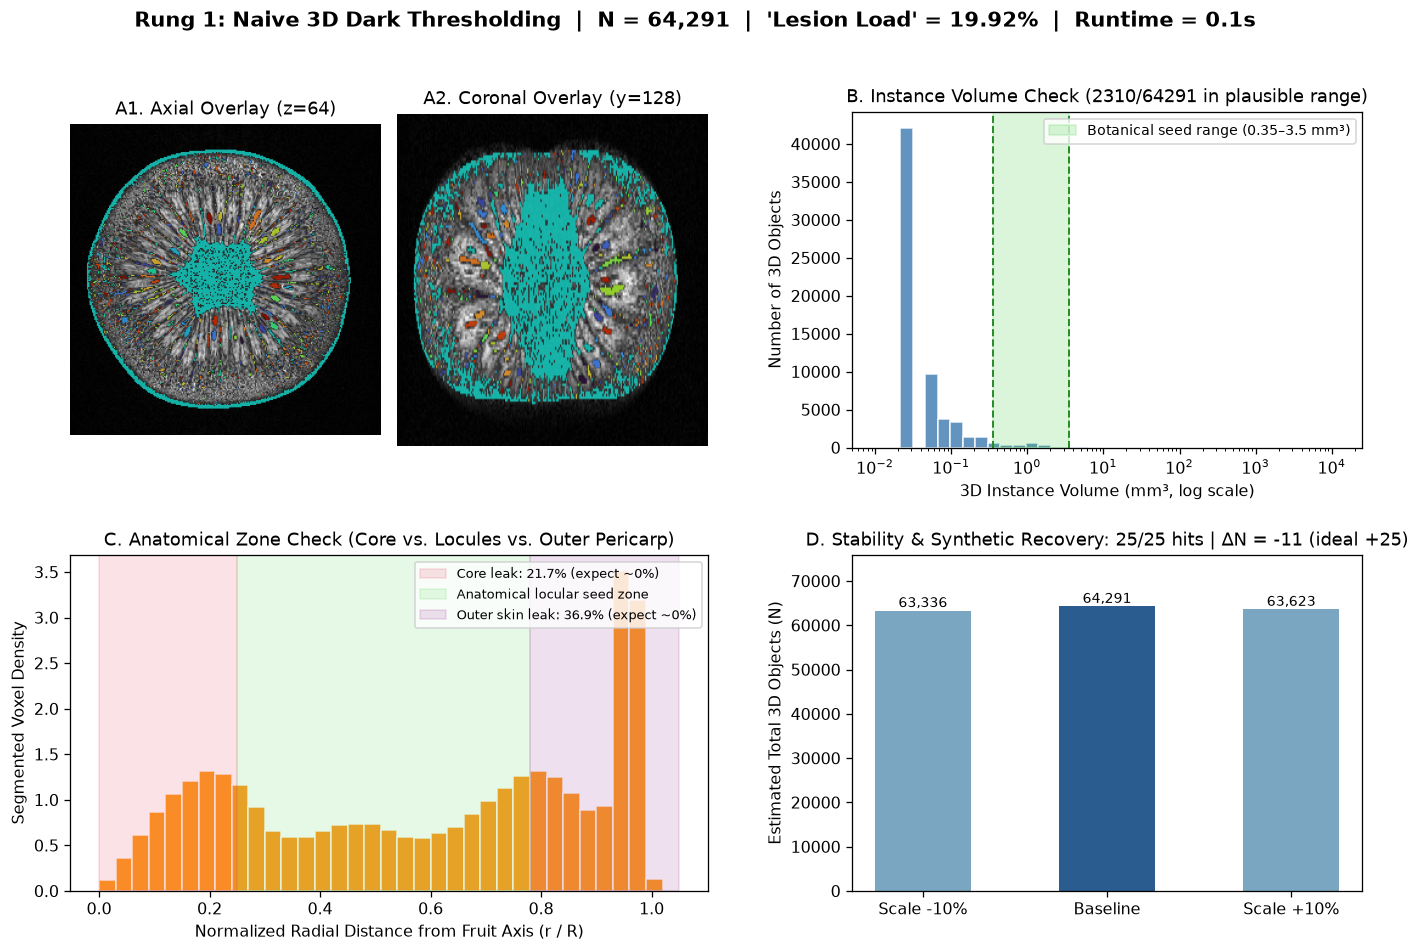

In [4]:
def segment_rung1_naive_threshold(volume, interior_mask, scale=1.0):
    """Rung 1: Simple global dark-intensity threshold inside the fruit interior."""
    thr = np.quantile(volume[interior_mask], 0.22) * scale
    binary_dark = (volume < thr) & interior_mask
    labels, _ = ndi.label(binary_dark)
    return labels


metrics_r1, labels_r1 = evaluate_and_plot_dashboard(
    "Rung 1: Naive 3D Dark Thresholding", segment_rung1_naive_threshold
)

**What did the dashboard catch in Rung 1?**
- **Panel A & C (Anatomy):** Over `20%` of segmented voxels sit inside the dark star-shaped central columella and nearly `40%` sit in the speckled outer pericarp!
- **Panel B (Volume physics):** The median object is a single voxel (`0.03 mm³` noise speck, `> 60,000` objects total!), while the largest single connected component exceeds **`12,000 mm³`** (`12 cm³` — the entire central core fused into one giant "seed").
- **Panel D (Subtle trap!):** Notice that Rung 1 still hit `25/25` synthetic seeds locally because those synthetic seeds were placed in bright mucilage where they didn't touch the core — **yet** $\Delta\hat{N}$ was *negative* instead of `+25`, and Panels B & C exposed massive false positives elsewhere. This shows why **multiple orthogonal checks** are essential!

---

## Step 3 — Rung 2A: 2D Black Top-Hat + K-Means Clustering

In `02-kiwi-seeds-explore.ipynb`, we explored **morphological grey closing** (*black top-hat* filtering) combined with **K-means clustering** on a single 2D slice:
- Closing an image with a small 2D disk (`radius = 5 px ≈ 1.17 mm`) fills in **narrow** dark structures (such as seeds) while leaving **wide** dark regions (the central columella!) unchanged.
- Subtracting the original slice from the closed slice (`black_tophat = closed - original`) highlights narrow dark pockets.

Let us apply this 2D slice-by-slice feature stack (`[intensity, local_background, 2D_black_tophat]`) + `MiniBatchKMeans` across all 128 slices and inspect our 4-panel dashboard.

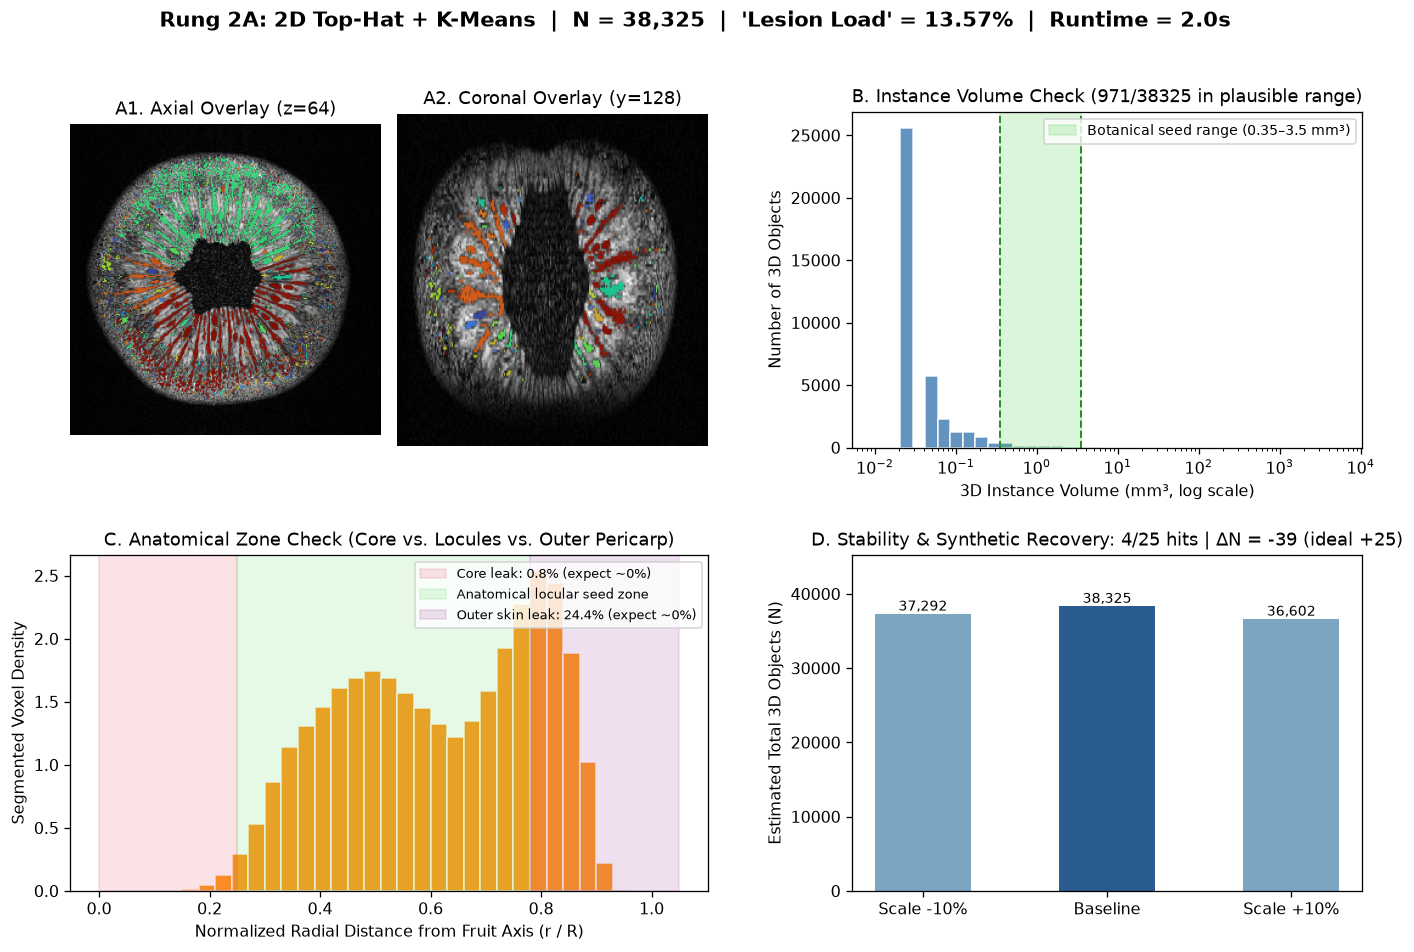

In [5]:
def segment_rung2a_2d_tophat_kmeans(volume, interior_mask, scale=1.0):
    """Rung 2A: Slice-by-slice 2D black top-hat features + unsupervised K-means clustering."""
    selem2d = morphology.disk(5)  # ~1.17 mm radius in-plane
    tophat_3d = np.zeros_like(volume)
    local_bg_3d = np.zeros_like(volume)

    for z in range(volume.shape[2]):
        sl = volume[:, :, z]
        closed = ndi.grey_closing(sl, footprint=selem2d)
        tophat_3d[:, :, z] = closed - sl
        local_bg_3d[:, :, z] = ndi.gaussian_filter(sl, sigma=4.0)

    idx = np.flatnonzero(interior_mask)
    X = np.column_stack([
        volume.ravel()[idx],
        local_bg_3d.ravel()[idx],
        tophat_3d.ravel()[idx],
    ])
    Xz = (X - X.mean(axis=0)) / (X.std(axis=0) + 1e-6)

    km = MiniBatchKMeans(n_clusters=4, random_state=42, batch_size=8192, n_init=5)
    clusters = km.fit_predict(Xz)
    seed_cluster = int(np.argmax(km.cluster_centers_[:, 2]))  # highest black top-hat centroid

    thr_th = np.percentile(tophat_3d.ravel()[idx], 85) * scale
    fg_flat = np.zeros(volume.size, dtype=bool)
    fg_flat[idx] = (clusters == seed_cluster) & (tophat_3d.ravel()[idx] > thr_th)

    labels, _ = ndi.label(fg_flat.reshape(volume.shape))
    return labels


metrics_r2a, labels_r2a = evaluate_and_plot_dashboard(
    "Rung 2A: 2D Top-Hat + K-Means", segment_rung2a_2d_tophat_kmeans
)

**Progress — and a revealing geometric failure in Rung 2A:**
- **Big win on the core:** Central columella leakage dropped from **`~22%` down to `< 1%`**! Because the central core is much wider than `1.2 mm`, morphological closing no longer mistakes it for seeds.
- **Why does Rung 2A still fail?** Look at Panel A1: **thin radial septa (locular walls)** between seed chambers are also narrow (`~0.5 mm` thick), even though they are long planar sheets rather than compact 3D seeds! Consequently, 2D closing highlights the radial walls, connecting seeds and walls into giant purple webs (`max > 9,000 mm³`) alongside thousands of tiny outer-pericarp pores.

---

## Step 4 — Rung 2B: 3D Anisotropic Seedness + Bright-Locule Context + 3D Watershed

Now let us combine **physical MRI geometry** with **botanical domain priors** directly in 3D:

1. **Anisotropic 3D Ellipsoidal Closing (`spacing = 0.234 × 0.234 × 0.500 mm`):** Build a physical 3D ellipsoid footprint (`~1.15 mm` in-plane radius, `~1.50 mm` axial radius) matched to real voxel dimensions rather than raw pixel counts.
2. **Bright-Locule Context Envelope:** Real seeds are embedded inside water-rich, **bright** mucilaginous locular gel (`bright_env`), whereas dark pores in the outer pericarp sit in much dimmer tissue. Normalizing the local intensity drop (`rel_drop = (closed_3d - v_den) / (bright_env + 1000)`) and requiring a bright surrounding envelope cleanly suppresses outer-pericarp noise without hard-coding slice numbers.
3. **3D Marker-Controlled Watershed:** Seeds sitting end-to-end inside the same radial locule often touch across 1–2 partial-volume voxels. Using the 3D physical Euclidean distance transform (`ndi.distance_transform_edt(..., sampling=spacing)`) combined with seedness peaks splits touching seeds at their narrowest neck.
4. **3D Instance Shape & Contrast Filter:** Reject tiny noise (`< 0.28 mm³`) and thin diagonal septum sheets (low 3D bounding-box `extent < 0.24` or insufficiently dark core).

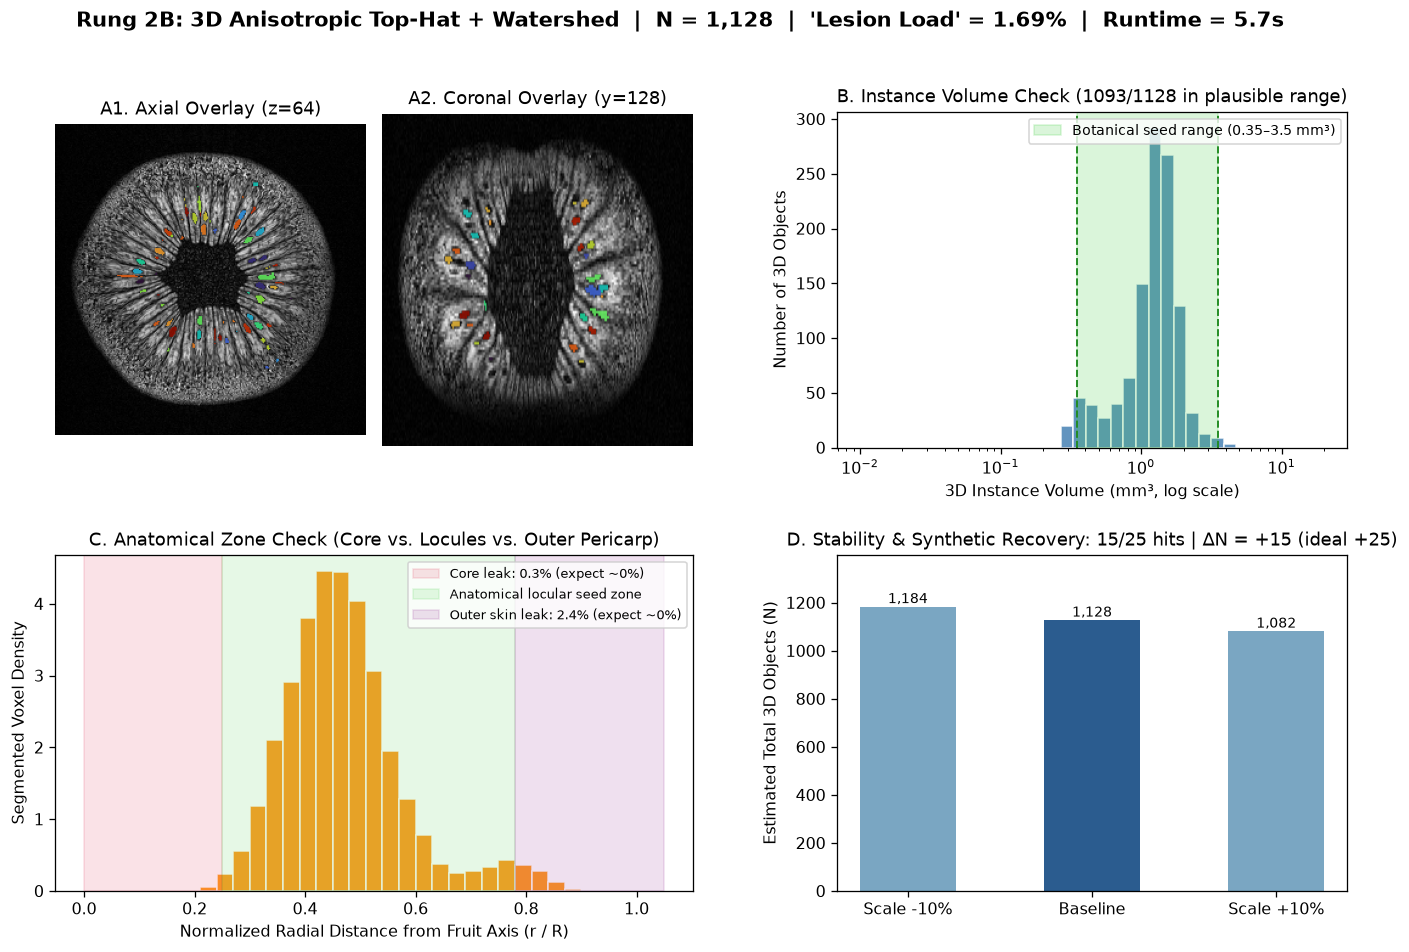

In [6]:
def build_ellipsoid_footprint(rx_mm, rz_mm, sp=spacing):
    """Create a 3D boolean ellipsoid structuring element in physical millimeter units."""
    rx = int(np.ceil(rx_mm / sp[0]))
    ry = int(np.ceil(rx_mm / sp[1]))
    rz = int(np.ceil(rz_mm / sp[2]))
    xx, yy, zz = np.ogrid[-rx : rx + 1, -ry : ry + 1, -rz : rz + 1]
    return ((xx * sp[0] / rx_mm) ** 2 + (yy * sp[1] / rx_mm) ** 2 + (zz * sp[2] / rz_mm) ** 2) <= 1.0


def segment_rung2b_3d_anisotropic_watershed(volume, interior_mask, sp=spacing, scale=1.0):
    """Rung 2B: 3D anisotropic black top-hat + bright-locule context + 3D watershed + 3D shape check."""
    # 1. Light edge-preserving 3D smoothing in physical mm
    v_den = ndi.gaussian_filter(volume, sigma=(0.20 / sp[0], 0.20 / sp[1], 0.25 / sp[2]))

    # 2. 3D physical ellipsoidal closing to estimate the surrounding bright locular tissue envelope
    fp_close = build_ellipsoid_footprint(rx_mm=1.15, rz_mm=1.50, sp=sp)
    closed_3d = ndi.grey_closing(v_den, footprint=fp_close)
    bright_env = ndi.gaussian_filter(closed_3d, sigma=(1.2 / sp[0], 1.2 / sp[1], 1.2 / sp[2]))

    # 3. Relative 3D intensity drop inside bright mucilaginous locular tissue
    rel_drop = (closed_3d - v_den) / (bright_env + 1000.0)
    env_thr = np.percentile(bright_env[interior_mask], 56)
    fg_seeds = (
        (rel_drop > 0.30 * scale)
        & (bright_env > env_thr)
        & (v_den < (0.48 / np.sqrt(scale)) * bright_env)
        & interior_mask
    )

    # 4. 3D marker-controlled watershed in physical millimeter coordinates to split touching seeds
    dist_mm = ndi.distance_transform_edt(fg_seeds, sampling=sp)
    peak_field = ndi.gaussian_filter(
        dist_mm * (0.5 + rel_drop),
        sigma=(0.28 / sp[0], 0.28 / sp[1], 0.38 / sp[2]),
    )
    fp_peak = build_ellipsoid_footprint(rx_mm=0.78, rz_mm=1.05, sp=sp)
    local_max = (
        (peak_field == ndi.maximum_filter(peak_field, footprint=fp_peak))
        & fg_seeds
        & (dist_mm >= 0.22)
    )
    markers, _ = ndi.label(local_max)
    ws = segmentation.watershed(-peak_field, markers=markers, mask=fg_seeds)

    # 5. Instance-level physical volume, core-darkness, and 3D compactness check
    clean_labels = np.zeros_like(ws)
    new_id = 0
    vox_vol = float(np.prod(sp))
    for prop in measure.regionprops(ws, intensity_image=v_den):
        v_mm3 = prop.area * vox_vol
        if not (0.28 <= v_mm3 <= 4.8):
            continue
        cx, cy, cz = [int(round(c)) for c in prop.centroid]
        if prop.intensity_min > (0.37 / np.sqrt(scale)) * bright_env[cx, cy, cz]:
            continue
        if prop.extent < 0.24:  # rejects thin planar radial septa while keeping ovoid 3D seeds
            continue
        new_id += 1
        coords = prop.coords
        clean_labels[coords[:, 0], coords[:, 1], coords[:, 2]] = new_id

    return clean_labels


metrics_r2b, labels_r2b = evaluate_and_plot_dashboard(
    "Rung 2B: 3D Anisotropic Top-Hat + Watershed", segment_rung2b_3d_anisotropic_watershed
)

---

## Step 5 — Side-by-Side Comparison & Zoomed Visual "Micro-Audit"

Let us summarize all three rungs in a single quantitative table, and then zoom into three consecutive slices (`z = 63, 64, 65`) of a high-contrast radial sector so you can **audit individual seeds with your own eyes** (count true positives, false positives, and any missed faint seeds!).

In [7]:
summary_df = pd.DataFrame([metrics_r1, metrics_r2a, metrics_r2b]).set_index("Method")
display(summary_df)

print(
    f"\nRung 2B Quantitative Biomarker Summary:"
    f"\n  - Estimated seed count (N)   : {metrics_r2b['Total Objects (N)']:,} seeds "
    f"(±10% sensitivity interval: {metrics_r2b['Sensitivity Range (±10%)']})"
    f"\n  - Whole-kiwi ('brain') vol.  : {fruit_vol_cm3:.2f} cm^3"
    f"\n  - Total seed ('lesion') vol. : {metrics_r2b['Seed Vol (cm³)']:.2f} cm^3 "
    f"(median single seed = {metrics_r2b['Median Vol (mm³)']:.2f} mm^3)"
    f"\n  - Kiwi 'Lesion Load'         : {metrics_r2b['Lesion Load (%)']:.2f}% of whole-fruit volume"
)

,Total Objects (N),Sensitivity Range (±10%),Plausible Seeds (0.35–3.5 mm³),Median Vol (mm³),Max Vol (mm³),Core Leak (%),Outer Skin Leak (%),Synthetic Recall (/25),Synthetic ΔN (ideal +25),Lesion Load (%),Seed Vol (cm³)
Method,,,,,,,,,,,
Rung 1: Naive 3D Dark Thresholding,64291,"[63,336 – 63,623]",2310,0.03,11300.4,21.74,36.93,25/25,-11,19.92,17.13
Rung 2A: 2D Top-Hat + K-Means,38325,"[36,602 – 37,292]",971,0.03,4889.4,0.80,24.36,4/25,-39,13.57,11.67
Rung 2B: 3D Anisotropic Top-Hat + Watershed,1128,"[1,082 – 1,184]",1093,1.29,4.1,0.33,2.41,15/25,+15,1.69,1.45



Rung 2B Quantitative Biomarker Summary:
  - Estimated seed count (N)   : 1,128 seeds (±10% sensitivity interval: [1,082 – 1,184])
  - Whole-kiwi ('brain') vol.  : 85.97 cm^3
  - Total seed ('lesion') vol. : 1.45 cm^3 (median single seed = 1.29 mm^3)
  - Kiwi 'Lesion Load'         : 1.69% of whole-fruit volume


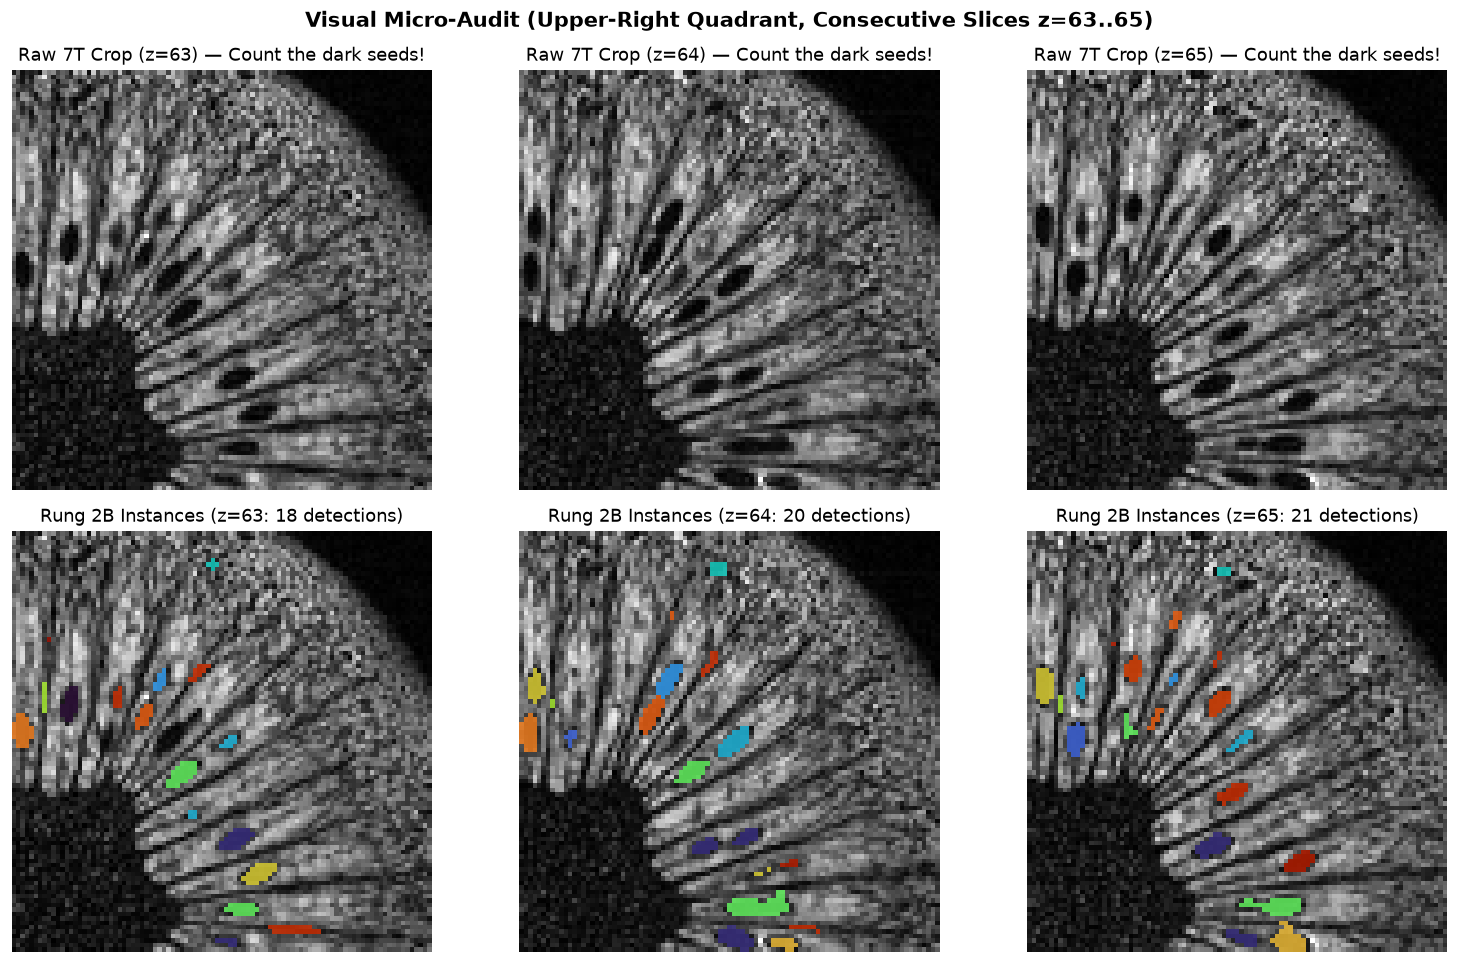

In [8]:
# Zoomed 3-slice Micro-Audit on upper-right radial locules (x: 120..215, y: 120..215, z: 63..65)
x_sl, y_sl = slice(120, 215), slice(120, 215)
audit_slices = [63, 64, 65]

fig, axes = plt.subplots(2, 3, figsize=(13.5, 8.5))
for col, z in enumerate(audit_slices):
    raw_crop = vol[x_sl, y_sl, z].T
    lbl_crop = labels_r2b[x_sl, y_sl, z].T

    axes[0, col].imshow(raw_crop, cmap="gray", origin="lower")
    axes[0, col].set_title(f"Raw 7T Crop (z={z}) — Count the dark seeds!")

    axes[1, col].imshow(raw_crop, cmap="gray", origin="lower")
    ov = np.ma.masked_where(lbl_crop == 0, ((lbl_crop * 7) % 23) + 1)
    axes[1, col].imshow(ov, cmap="turbo", alpha=0.82, origin="lower", vmin=1, vmax=24)
    n_in_crop = len(np.unique(lbl_crop)) - (1 if 0 in lbl_crop else 0)
    axes[1, col].set_title(f"Rung 2B Instances (z={z}: {n_in_crop} detections)")

for ax in axes.ravel():
    ax.axis("off")

fig.suptitle(
    "Visual Micro-Audit (Upper-Right Quadrant, Consecutive Slices z=63..65)",
    fontsize=13,
    fontweight="bold",
)
plt.tight_layout()
plt.show()

---

## Next Steps: Rungs 3–5 (Foundation Models, 3D Deep Learning & Verifier-Guided Agents)

Even though **Rung 2B** needs zero training labels and runs in a few seconds on a laptop CPU, look closely at the zoomed Micro-Audit above:
- Can you spot **1–2 faint partial-volume seeds** near the outer ends of the locules that fell just below the contrast threshold (*false negatives*)?
- Or **two tightly packed seeds** whose boundary watershed split slightly off-center?

That sets up **Rungs 3–5** for discussion in **Lab 4** (and as a ready-made benchmark if you choose the Kiwi Challenge for your **Block 2 Individual Project**):

1. **Rung 3 — Zero-Shot Vision Foundation Models (`SAM 2` / `MedSAM` / `MicroSAM` / `Cellpose` / `StarDist`):**
   - Run a pretrained instance segmenter on axial slices and test how you stitch 2D slice masks into 3D instances without double-counting seeds across `0.5 mm` slices.
2. **Rung 4 — Sparse-Label 3D Deep Learning + Neurosymbolic Priors:**
   - Manually annotate all seeds in just **5 contiguous slices** (using [ITK-SNAP](http://www.itksnap.org/) or [3D Slicer](https://www.slicer.org/)), train a lightweight 3D U-Net (`MONAI`) or `StarDist-3D`, and apply physical volume + radial-zone priors.
3. **Rung 5 — Verifier-Guided AI Coding Agent Experiment:**
   - Compare what happens when you give an AI coding assistant *(a)* a vague prompt (*"Count the seeds in this NIfTI file"*) versus *(b)* **closed-loop access to `evaluate_and_plot_dashboard(...)`**:
   > *Example agent prompt:*  
   > `"Goal: Improve 3D seed instance segmentation on kiwi_20050217191129_131073_RARE_high_res_axial.nii.gz. Every candidate function must be evaluated with evaluate_and_plot_dashboard(). Aim for >= 24/25 synthetic recall, ΔN within [22, 28], < 1% core and outer-skin leakage, >= 95% of detections within 0.35–3.5 mm³, and visually clean separation in the z=63..65 micro-audit crop."`

---

### Where to Go Next in the Kiwi Challenge Trilogy

- **Notebook 01 (`01-kiwi-explore.ipynb`):** 3D NIfTI/DICOM headers, physical voxel geometry & affine coordinate systems
- **Notebook 02 (`02-kiwi-seeds-explore.ipynb`):** 2D single-slice filtering, thresholding, unsupervised K-means & the 2011–2012 Dagstuhl / CUHK 3D variational segmentation milestone
- **Notebook 03 (`03-kiwi-paradigms-and-verification.ipynb`):** Full 3D segmentation ladder (Rung 1 → Rung 2B → Foundation Models & Agents), quantitative "lesion load", & the **4-Panel Semi-Verifiability Dashboard**
